 # Этап 1: знакомство с данными и EDA (Exploratory Data Analysis)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Загрузка данных:

In [2]:
df_book_tags = pd.read_csv("data/book_tags.csv")
df_books = pd.read_csv("data/books.csv")
df_ratings = pd.read_csv("data/ratings.csv")
df_tags = pd.read_csv("data/tags.csv")

df_ratings.head()

,book_id,user_id,rating
0,1,314,5
1,1,439,3
2,1,588,5
3,1,1169,4
4,1,1185,4


In [3]:
df_book_tags.head()

,goodreads_book_id,tag_id,count
0,1,30574,167697
1,1,11305,37174
2,1,11557,34173
3,1,8717,12986
4,1,33114,12716


In [4]:
df_books.head()

,id,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


In [5]:
df_tags.head()

,tag_id,tag_name
0,0,-
1,1,--1-
2,2,--10-
3,3,--12-
4,4,--122-


In [6]:
# Пропуски и дубликаты и отрицательные значения
print("NaN в ratings:", df_ratings.isna().sum().sum())
print("NaN в title:", df_books["title"].isna().sum())
print("NaN в original_title:", df_books["original_title"].isna().sum())

n_dup = df_ratings.duplicated(["user_id", "book_id"]).sum()
print(f"Дубли (user_id, book_id): {n_dup} ({n_dup / len(df_ratings):.2%})")

df_ratings = df_ratings.drop_duplicates(["user_id", "book_id"], keep="last")
df_book_tags = df_book_tags[df_book_tags["count"] > 0]

NaN в ratings: 0
NaN в title: 0
NaN в original_title: 585
Дубли (user_id, book_id): 2278 (0.23%)


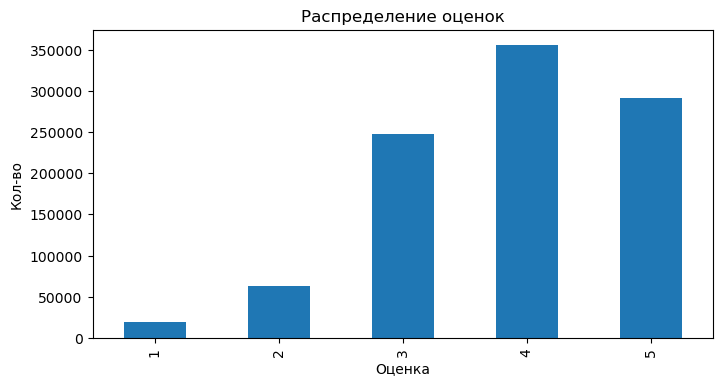

count    979478.000000
mean          3.856090
std           0.983899
min           1.000000
25%           3.000000
50%           4.000000
75%           5.000000
max           5.000000
Name: rating, dtype: float64

Процент оценок 4 и 5: 66.2%


In [7]:
# Смещение
plt.figure(figsize=(8,4))
df_ratings['rating'].value_counts().sort_index().plot(kind='bar')
plt.title('Распределение оценок')
plt.xlabel('Оценка')
plt.ylabel('Кол-во')
plt.show()

print(df_ratings['rating'].describe())
print(f"\nПроцент оценок 4 и 5: {(df_ratings['rating'] >= 4).mean():.1%}")

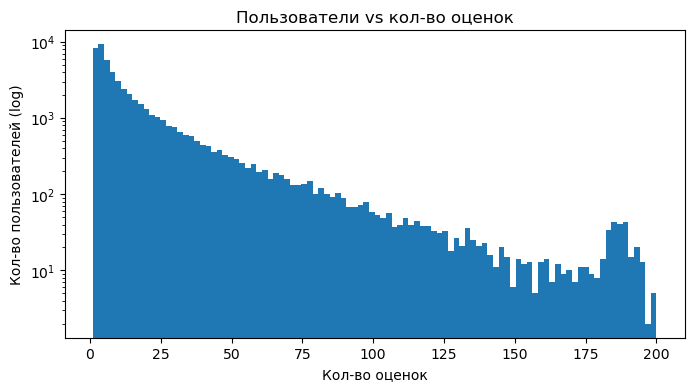

Всего пользователей: 53424
Холодный старт (меньше 5 оценок): 17765
Активных (более 50 оценок): 4908


In [8]:
# Активность пользователей
user_activity = df_ratings.groupby('user_id')['rating'].count()

plt.figure(figsize=(8,4))
plt.hist(user_activity, bins=100, log=True) 
plt.title('Пользователи vs кол-во оценок')
plt.xlabel('Кол-во оценок'); plt.ylabel('Кол-во пользователей (log)')
plt.show()

print(f'Всего пользователей: {len(user_activity)}')
print(f'Холодный старт (меньше 5 оценок): {(user_activity < 5).sum()}')
print(f'Активных (более 50 оценок): {(user_activity >= 50).sum()}')




In [9]:
# Анализ популярности книг
df_ratings.groupby('book_id')['rating'].count().describe().round(2)

count    10000.00
mean        97.95
std          5.76
min          8.00
25%         99.00
50%        100.00
75%        100.00
max        100.00
Name: rating, dtype: float64

- df_ratings - это сэмпл из Goodreads: на каждую книгу взято ~100 оценок.   
- df_books['ratings_count'] - это настоящее суммарное число оценок книги на Goodreads


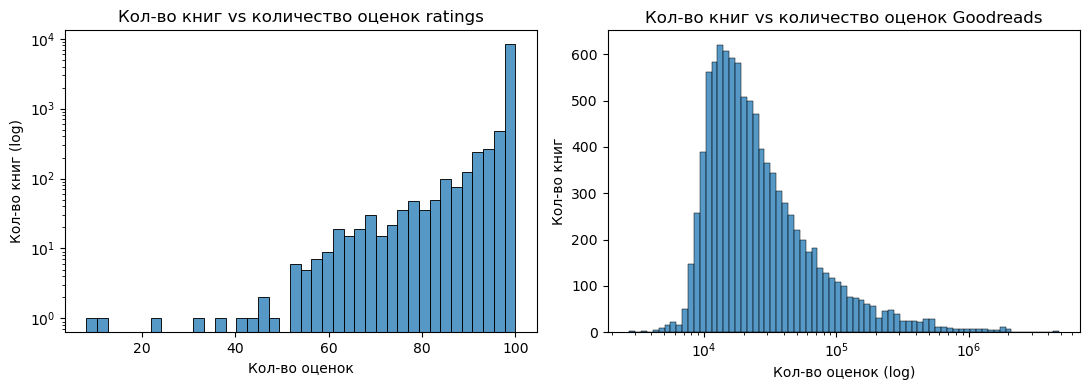

In [10]:
count_books = df_ratings.groupby("book_id").size()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(count_books, bins=40, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set(title="Кол-во книг vs количество оценок ratings", xlabel="Кол-во оценок", ylabel="Кол-во книг (log)")

sns.histplot(df_books["ratings_count"], log_scale=True, ax=axes[1])
axes[1].set(title="Кол-во книг vs количество оценок Goodreads", xlabel="Кол-во оценок (log)", ylabel="Кол-во книг")

plt.tight_layout()
plt.show()

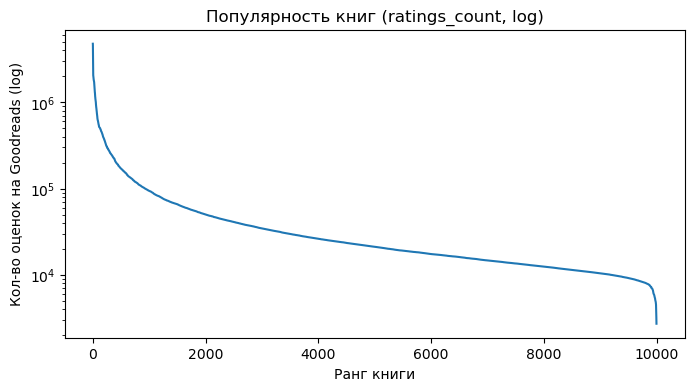

Доля оценок у топ-1% книг: 23.4 %
Доля оценок у топ-10% книг: 57.1 %


In [11]:
# Анализ популярности книг
popular_books = df_books['ratings_count'].sort_values(ascending=False).reset_index(drop=True)

plt.figure(figsize=(8,4))
plt.plot(range(len(popular_books)), popular_books)
plt.yscale('log')
plt.title('Популярность книг (ratings_count, log)')
plt.xlabel('Ранг книги'); plt.ylabel('Кол-во оценок на Goodreads (log)')
plt.show()

print('Доля оценок у топ-1% книг:', round(popular_books.head(int(len(popular_books)*0.01)).sum()*100/popular_books.sum(), 1),'%')
print('Доля оценок у топ-10% книг:', round(popular_books.head(int(len(popular_books)*0.1)).sum()*100/popular_books.sum(), 1),'%')


In [12]:
# популярные книги
df_books.nlargest(10, "ratings_count")[["title", "authors", "average_rating", "ratings_count"]]

,title,authors,average_rating,ratings_count
0,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,4.34,4780653
1,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",4.44,4602479
2,"Twilight (Twilight, #1)",Stephenie Meyer,3.57,3866839
3,To Kill a Mockingbird,Harper Lee,4.25,3198671
4,The Great Gatsby,F. Scott Fitzgerald,3.89,2683664
5,The Fault in Our Stars,John Green,4.26,2346404
6,The Hobbit,J.R.R. Tolkien,4.25,2071616
7,The Catcher in the Rye,J.D. Salinger,3.79,2044241
9,Pride and Prejudice,Jane Austen,4.24,2035490
8,"Angels & Demons (Robert Langdon, #1)",Dan Brown,3.85,2001311


In [13]:
# Медиана
df_books['ratings_count'].sort_values(ascending=False).median()

21155.5

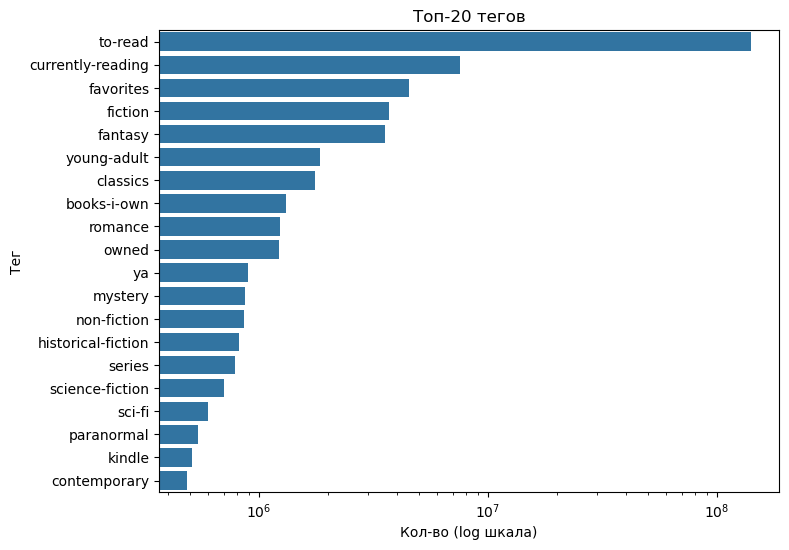

In [14]:
# Теги
tag_counts = df_book_tags.groupby('tag_id')['count'].sum().sort_values(ascending=False).head(20)

top_tags = tag_counts.to_frame('count').join(df_tags.set_index('tag_id')['tag_name'])

plt.figure(figsize=(8,6))
sns.barplot(x=top_tags['count'], y=top_tags['tag_name'])
plt.xscale('log')
plt.title('Топ-20 тегов')
plt.xlabel('Кол-во (log шкала)'); plt.ylabel('Тег')
plt.show()


In [15]:
# Разреженность
n_users = df_ratings['user_id'].nunique()
n_books = df_ratings['book_id'].nunique()
density = len(df_ratings) / (n_users * n_books)
print(f'Пользователей: {n_users}, книг с оценками: {n_books}, оценок: {len(df_ratings)}')
print(f'Плотность: {density*100:.3f}% (разреженность {1-density:.5f})')

Пользователей: 53424, книг с оценками: 10000, оценок: 979478
Плотность: 0.183% (разреженность 0.99817)


## Выводы по Этапу 1  
#### Смещение:
Наблюдается систематический сдвиг оценок вверх: 2/3 всех оценок составляют 4 и 5. Пользователи чаще оценивают понравившиеся книги
«средняя» тройка по сути ближе к отрицательной оценке, так что стоит рассмотреть порог релевантности равным 4.

---
#### Анализ активности пользователей:
Распределение сильно скошено вправо. У трети пользователей (17 714 из 53 424 - это 33%) меньше пяти оценок, а активных (больше 50 оценок) всего 9% (4 927 человек). Пользователи с 1–4 оценками - холодный старт, для них необходимо использовать, например, вариант популярных рекомендаций.

---
#### Анализ популярности книг:
По Goodreads хвост виден хорошо: топ-книги имеют 3.9–4.8 млн оценок против ~21 тыс. у медианной. топ-1% книг даёт 23% оценок, топ-10% - 57%. И это уже внутри 10 000 самых популярных книг.  
В ratings.csv перекоса нет: у ~80% книг 99–100 оценок, поэтому популярность как сигнал для рекомендаций здесь не работает - учтём это при оценке моделей.
Топ 3 популярных книги
- The Hunger Games (The Hunger Games, #1)
- Harry Potter and the Sorcerer's Stone 
- Twilight (Twilight, #1)

---
#### Визуализация тегов
жанровый сигнал в тегах есть (fiction, fantasy, young-adult, classics, romance, mystery), хотя запись дублируется (young-adult/ya, science-fiction/sci-fi, non-fiction/nonfiction). Теги шумные, но контентная модель сможет на них опереться. Служебные вроде to-read стоят почти у всех книг - отдельная фильтрация не критична, TF-IDF в таком случае сам даст им малый вес.

---
#### Проблемы данных
- Качество данных. Повторы оценок, пропуски в названиях, шумные и дублирующиеся теги. Временных меток нет - разбиение на train/test будет случайным.
- Смещение оценок. 66% оценок - 4 и 5. Пользователи оценивают то, что выбрали и дочитали, поэтому пропуски не случайны: отсутствие оценки чаще значит «не интересно», чем «не видел». Модель, хорошо предсказывающая оценки на выбранных книгах, не обязательно хорошо выбирает книги из каталога.
- Смещение популярности. По Goodreads 10% книг собирают 57% оценок: модель будет рекомендовать бестселлеры, а хвост останется без показов и новых оценок. В ratings.csv перекос ослаблен сэмплированием (≤100 оценок на книгу), но пользовательский перекос остался. 
- Холодный старт. У трети пользователей <5 оценок, у половины <10 - персональные рекомендации для них ненадёжны, а для новых пользователей и книг коллаборативные методы не работают вовсе. Со стороны книг проблема сглажена сэмплом (у всех ~100 оценок), но в реальном сервисе новые книги появляются постоянно.
- Разреженность. Матрица «пользователь - книга» заполнена на 0.18%: в среднем 18 оценок из 10 000 книг на пользователя. У случайных пользователей/книг общих оценок часто нет вовсе

# Этап 2: базовые и контентные модели

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel
from sklearn.metrics.pairwise import cosine_similarity

In [17]:
# Разбиение на train и test 80/20
from sklearn.model_selection import train_test_split

train, test = train_test_split(
    df_ratings,
    test_size=0.2,
    random_state=42,
)

print(f"train: {len(train)} оценок ({len(train) / len(df_ratings) * 100:.0f}%)")
print(f"test:  {len(test)} оценок ({len(test) / len(df_ratings) * 100:.0f}%)")

print(f"\nДоля оценок >= 4 в train: {(train['rating'] >= 4).mean():.1%}")
print(f"Доля оценок >= 4 в test:  {(test['rating'] >= 4).mean():.1%}")

train_users = set(train['user_id'])
test_users = set(test['user_id'])

print(f"\nПользователи train: {len(train_users)}, в test: {len(test_users)}")
print(f"Пользователи test (отсутствующие в train): {len(test_users - train_users)}")

train: 783582 оценок (80%)
test:  195896 оценок (20%)

Доля оценок >= 4 в train: 66.3%
Доля оценок >= 4 в test:  66.1%

Пользователи train: 52985, в test: 40420
Пользователи test (отсутствующие в train): 439


Данные не искажены случайным разбиением.  
439 пользователей с короткой историей - холодный старт.  
test далее используется только для оценки качества на этапах 4 и 5. 

## Неперсонализированная модель

In [18]:
train.groupby("book_id").size().describe().round(1)

count    10000.0
mean        78.4
std          6.0
min          6.0
25%         76.0
50%         79.0
75%         82.0
max         93.0
dtype: float64

In [ ]:
# В train у книги в среднем 78 оценок, берём порог 40.
# Отсекаем книги с малым числом оценоки оставляем большую часть каталога.

stats = train.groupby('book_id').agg(
    n_ratings=('rating', 'count'),
    mean_rating=('rating', 'mean'),
)
popularity = stats[stats['n_ratings'] >= 40]
popularity = popularity.sort_values(['mean_rating', 'n_ratings'], ascending=False)

print(f"Книг, прошедших порог: {len(popularity)} из {len(stats)}")

book_info = df_books.set_index('id')[['title', 'authors']]
def get_popular_books(N=10):
    top_books = popularity.head(N).join(book_info)
    top_books = top_books.reset_index()
    return top_books[['book_id', 'title', 'authors', 'n_ratings', 'mean_rating']]


print("Top-10 популярных книг в train:")
display(get_popular_books(N=10))


Книг, прошедших порог: 9990 из 10000
Top-10 популярных книг в train:


,book_id,title,authors,n_ratings,mean_rating
0,7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem",63,4.888889
1,5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson,81,4.814815
2,9566,Attack of the Deranged Mutant Killer Monster S...,Bill Watterson,85,4.800000
3,8978,The Revenge of the Baby-Sat,Bill Watterson,71,4.788732
4,6920,The Indispensable Calvin and Hobbes,Bill Watterson,80,4.787500
5,3275,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling, Mary GrandPré",82,4.780488
6,8663,"Locke & Key, Vol. 6: Alpha & Omega","Joe Hill, Gabriel Rodríguez",73,4.767123
7,3753,"Harry Potter Collection (Harry Potter, #1-6)",J.K. Rowling,80,4.750000
8,6361,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson,80,4.750000
9,4483,It's a Magical World: A Calvin and Hobbes Coll...,Bill Watterson,78,4.743590


## Контентная модель: TF-IDF

Объединяю книги с тегами.
Для каждой книги собираю текстовый профиль - название (original_title) и список тегов.
Векторизую профили через TF-IDF.
Реализую get_similar_books(book_id, N=5): находит N самых похожих книг по косинусной близости между TF-IDF-векторами.

In [20]:
# Сервисные теги
service_tags = [
    'to-read', 'currently-reading', 'read-in-2011', 'read-in-2012', 'read-in-2013', 'read-in-2014', 'read-in-2015',
    'read-in-2016', 'read-in-2017', 'read-2014', 'read-2015', 'read-2016', 're-read', 're_reading', 'rereads', 'dnf', 'did-not-finish', 'abandoned', 'maybe', 
    'owned', 'books-i-own', 'owned-books', 'i-own', 'own-it', 'have', 'my-books', 'my-library', 'library', 'home-library', 'borrowed',
    'to-buy', 'wish-list', 'default', 'books', 'kindle', 'ebook', 'ebooks', 'e-book', 'e-books', 
    'audiobook', 'audiobooks', 'audio', 'audible', 'audio-book', 'audio-books', 'favorites', "series", 
    'favourites', 'favorite', 'favorite-books','all-time-favorites', 'shelfari-favorites', 'book-club', 'bookclub'
]

# Объединяем данные о книгах с тегами

book_id_map = df_books[['id', 'book_id']].rename(columns={'id': 'book_id', 'book_id': 'goodreads_book_id'})

# Оставляю только содержательные теги и добавляем к ним внутренний id книги
book_tags_named = df_book_tags.merge(df_tags, on='tag_id', how='left')
content_tags = book_tags_named[~book_tags_named['tag_name'].isin(service_tags)]
content_tags = content_tags.merge(book_id_map, on='goodreads_book_id', how='inner')
content_tags['tag_token'] = content_tags['tag_name'].str.replace('-', '_')

tags_text = content_tags.groupby('book_id')['tag_token'].apply(' '.join)
print(f"Среднее кол-во тегов на книгу {content_tags.groupby('book_id').size().mean():.1f}")


# Текстовый профиль книги: название + список тегов
book_titles = df_books['original_title'].copy()
empty_title_mask = book_titles.isnull() | (book_titles.str.strip() == '')
book_titles.loc[empty_title_mask] = df_books.loc[empty_title_mask, 'title']

content_books = pd.DataFrame({
    'book_id': df_books['id'],
    'title': df_books['title'],
    'authors': df_books['authors'],
    'profile_title': book_titles,
})
content_books['profile_tags'] = content_books['book_id'].map(tags_text).fillna('')
content_books['profile'] = content_books['profile_title'] + ' ' + content_books['profile_tags']
content_books = content_books.sort_values('book_id').reset_index(drop=True)


book_position = pd.Series(content_books.index, index=content_books['book_id'])
print("Пример случайного профиля:")
print(content_books.loc[book_position[5], 'profile'][:200])

Среднее кол-во тегов на книгу 71.6
Пример случайного профиля:
The Great Gatsby classics fiction classic literature school historical_fiction romance novels read_for_school american_literature high_school american historical for_school adult school_books classic_


In [21]:
# Векторизация
tfidf_vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(content_books['profile'])

n_rows, n_terms = tfidf_matrix.shape
tfidf_density = tfidf_matrix.nnz / (n_rows * n_terms) * 100

print(f"Размер: {n_rows} книг x {n_terms} терминов")
print(f"Ненулевых значений: {tfidf_matrix.nnz} (плотность {tfidf_density:.3f}%)")

Размер: 10000 книг x 40387 терминов
Ненулевых значений: 733328 (плотность 0.182%)


- Матрица 10 000 x 40 389 заполнена на 0.182%. Оставляю её в разреженном виде.

In [22]:
# Проверка на примере книги The Great Gatsby
terms = tfidf_vectorizer.get_feature_names_out()
example_vector = tfidf_matrix[book_position[5]].toarray().flatten()
top_term_positions = np.argsort(-example_vector)[:10]

print(f"Топ 10 тегов профиля книги '{content_books.loc[book_position[5], 'title']}':")
for term_position in top_term_positions:
    print(f"  {terms[term_position]:<25} {example_vector[term_position]:.3f}")

Топ 10 тегов профиля книги 'The Great Gatsby':
  gatsby                    0.278
  f_scott_fitzgerald        0.252
  great                     0.183
  read_in_high_school       0.182
  clàssics                  0.179
  1920s                     0.172
  american_classics         0.168
  to_read_again             0.167
  read_in_school            0.155
  required_reading          0.153


- самый большой вес получили редкие и специфичные термины: `gatsby`, `great`, `f_scott_fitzgerald`. 
- Частые теги: `read_in_school`, `clàssics`, `1920s` получили маленький вес TF-IDF отработал верно.
- Присутсвует шум `to_read_again`

### Поиск похожих книг по косинусной мере близости между их TF-IDF-векторами

In [23]:
# book_id - внутренний id (books.id), как в ratings.csv
def get_similar_books(book_id, N=5):
    idx = book_position[book_id]

    scores = cosine_similarity(tfidf_matrix[idx], tfidf_matrix).ravel()

    # ранжируем по убыванию, исключая саму книгу
    ranked = np.argsort(-scores)
    top_idx = [i for i in ranked if i != idx][:N]

    out = content_books.iloc[top_idx][['book_id', 'title', 'authors']].copy()
    out['similarity'] = scores[top_idx].round(3)
    return out.reset_index(drop=True)


# Проверка
sample_ids = [5, 250, 500]

for bid in sample_ids:
    row = content_books.iloc[book_position[bid]]
    print(f"Книга {bid}: {row['title']} ({row['authors']})")
    display(get_similar_books(bid, N=5))

Книга 5: The Great Gatsby (F. Scott Fitzgerald)


,book_id,title,authors,similarity
0,8,The Catcher in the Rye,J.D. Salinger,0.677
1,32,Of Mice and Men,John Steinbeck,0.612
2,4,To Kill a Mockingbird,Harper Lee,0.607
3,28,Lord of the Flies,William Golding,0.548
4,58,The Adventures of Huckleberry Finn,"Mark Twain, John Seelye, Guy Cardwell",0.494


Книга 250: Wonder (R.J. Palacio)


,book_id,title,authors,similarity
0,7989,The Julian Chapter (Wonder Story),R.J. Palacio,0.527
1,1558,Out of My Mind,Sharon M. Draper,0.421
2,3991,So B. It,Sarah Weeks,0.394
3,9069,A Corner of the Universe,Ann M. Martin,0.358
4,8059,Fish in a Tree,Lynda Mullaly Hunt,0.354


Книга 500: The Princess Diaries (The Princess Diaries, #1) (Meg Cabot)


,book_id,title,authors,similarity
0,3452,Princess in the Spotlight (The Princess Diarie...,Meg Cabot,0.829
1,4345,"Princess in Waiting (The Princess Diaries, #4)",Meg Cabot,0.821
2,3583,"Princess in Love (The Princess Diaries, #3)",Meg Cabot,0.792
3,5402,"Princess in Pink (The Princess Diaries, #5)",Meg Cabot,0.778
4,6201,"Princess in Training (The Princess Diaries, #6)",Meg Cabot,0.738


- Сильная сторона - «серийность». Для «The Princess Diaries» (0.74-0.83)
- Тематическое сходство работает слабее. У «The Great Gatsby» (0.49-0.68)
- Для «Wonder» результаты слабее (0.35-0.53): первая книга - прямое продолжение той же вселенной.



Сложность подхода: для одной книги близость со всеми - это по сути одно умножение разреженной строки на разреженную матрицу, то есть линейно по числу книг и размеру словаря; а если считать близость для всех пар книг сразу, сложность и память растут квадратично - это может быть критично.

Оптимизация для больших данных: хранить данные в разреженном виде, брать только топ-K без полной сортировки, кэшировать готовые результаты и сокращать словарь/размерность.







# Этап 3: коллаборативная фильтрация (Collaborative Filtering CF)

In [24]:
from scipy.sparse import csr_matrix
import time

In [25]:
# Матрица взаимодействий пользователь x книга со значениями оценок.
# Для нумерации начиная с id = 0.
train_values = train['rating'].values.astype(np.float64)
train_rows = train['user_id'].values - 1
train_cols = train['book_id'].values - 1

# csr т.к. заполнено меньше 0.2% ячеек
user_item_matrix = csr_matrix( 
    (train_values, (train_rows, train_cols)),
    shape=(n_users, n_books),
)

memory_mb = (
    user_item_matrix.data.nbytes
    + user_item_matrix.indices.nbytes
    + user_item_matrix.indptr.nbytes
) / 1024 / 1024

cnt_per_user = np.diff(user_item_matrix.indptr)          # оценок в каждой строке
active_users = int((cnt_per_user > 0).sum())

total_cells = n_users * n_books
density_pct = user_item_matrix.nnz / total_cells * 100

print(f"Размер матрицы: {n_users} x {n_books}")
print(f"Заполненные ячейки: {user_item_matrix.nnz} (плотность {density_pct:.3f}%)")
print(f"Память (csr_matrix): {memory_mb:.1f} МБ")

Размер матрицы: 53424 x 10000
Заполненные ячейки: 783582 (плотность 0.147%)
Память (csr_matrix): 9.2 МБ


Матрица 53 424 x 10 000 с 783 582 оценками занимает 9.2 МБ

### Матрица попарных схожестей книг


Расчет матрицы попарных схожестей между книгами (с помощью косинусной близости по векторам оценок).


In [26]:
# Матрица схожестей книг (косинус по столбцам оценок)
t0 = time.perf_counter()
item_similarity = cosine_similarity(user_item_matrix.T, dense_output=False).tocsr()
item_similarity.setdiag(0)
item_similarity.eliminate_zeros()
sim_sec = time.perf_counter() - t0

n_pairs = n_books * (n_books - 1)
sim_mem = (item_similarity.data.nbytes + item_similarity.indices.nbytes
           + item_similarity.indptr.nbytes) / 1024 / 1024
dense_mem = n_books * n_books * 8 / 1024 / 1024

print(f"Время: {sim_sec:.1f} с \nНенулевых схожестей: {item_similarity.nnz} "
      f"({item_similarity.nnz / n_pairs * 100:.1f}% пар)")
print(f"Память: {sim_mem:.0f} МБ разреженная vs {dense_mem:.0f} МБ плотная")

# Ближайший сосед каждой книги и число общих читателей
# Число общих читателей у книги с её ближайшим соседом
nearest = np.asarray(item_similarity.argmax(axis=1)).flatten()
binary = user_item_matrix.copy(); binary.data[:] = 1
common = (binary.T @ binary)[np.arange(n_books), nearest].A1
print(f"Общих читателей с соседом: медиана {np.median(common):.0f}")

# Примеры
for bid in [1, 5, 50, 250, 500]:
    i = bid - 1
    print(f"{book_info.loc[bid, 'title'][:40]:<42} -> "
          f"{book_info.loc[nearest[i] + 1, 'title'][:40]:<42} "
          f"sim={item_similarity[i, nearest[i]]:.2f}, общих={common[i]}")

Время: 0.7 с 
Ненулевых схожестей: 18330462 (18.3% пар)
Память: 210 МБ разреженная vs 763 МБ плотная
Общих читателей с соседом: медиана 21
The Hunger Games (The Hunger Games, #1)    -> Harry Potter and the Sorcerer's Stone (H   sim=0.46, общих=36.0
The Great Gatsby                           -> To Kill a Mockingbird                      sim=0.53, общих=41.0
Where the Sidewalk Ends                    -> The Giving Tree                            sim=0.44, общих=32.0
Wonder                                     -> Me Before You (Me Before You, #1)          sim=0.23, общих=19.0
The Princess Diaries (The Princess Diari   -> Princess in Love (The Princess Diaries,    sim=0.21, общих=18.0


- матрица схожестей считается за 0.6 с и хранится разреженно (210 МБ против 763 МБ плотной), но схожесть определена лишь для ~ 18% пар книг - у остальных нет общих читателей, это прямое следствие разреженности.
- У медианной книги с ближайшим соседом ~21 общий читатель
- CF находит «похожее по аудитории», а не по содержанию: у «The Hunger Games» сосед - «Гарри Поттер», у «The Great Gatsby» - «Убить пересмешника», у «Wonder» - «Me Before You» (схожесть всего 0.23, общих 19). 
- Самые активные пользователи читают популярные книги в том числе, поэтому они похожи друг на друга - это смещение популярности, ограничение item-based CF.



### Предсказание оценки, усредняя оценки пользователя по K наиболее похожим книгам.

Оценку пользователя u для книги i предсказываю как взвешенное среднее его оценок по K книгам, которые он уже оценил и которые наиболее похожи на i: чем выше схожесть, тем больше вес.




In [ ]:
# Запасные прогнозы: глобальное среднее и среднее по пользователю
global_mean_train = train['rating'].mean()
user_mean_train = train.groupby('user_id')['rating'].mean()

CF_K = 20   # отсечение слабо похожих книг, для большинства ничего не обрезает


def item_cf_scores(user_id, book_positions, K=CF_K):
    # Для книг book_positions (позиция = book_id - 1) возвращает:
    #   preds      - прогноз: взвешенное среднее оценок по K самым похожим книгам
    #   num        - сумма "схожесть x оценка" (числитель)
    #   den        - сумма схожестей (знаменатель)
    m = len(book_positions)

    urow = user_item_matrix[user_id - 1]
    rated_idx = urow.indices
    rated_vals = urow.data

    if rated_idx.size == 0:            # пользователя нет в train
        return np.full(m, global_mean_train), np.zeros(m), np.zeros(m)

    # Строки - целевые книги, столбцы - книги из истории пользователя
    S = item_similarity[rated_idx][:, book_positions].toarray().T

    # K самых похожих книг из истории пользователя для каждой целевой
    k_idx = np.argsort(-S, axis=1)[:, :K]
    k_sims = np.take_along_axis(S, k_idx, axis=1)
    k_vals = rated_vals[k_idx]

    num = (k_sims * k_vals).sum(axis=1)
    den = k_sims.sum(axis=1)

    preds = np.full(m, user_mean_train[user_id])
    ok = den > 0
    preds[ok] = num[ok] / den[ok]

    return preds, num, den


def predict_rating_item_cf(user_id, book_id, K=CF_K):
    preds, _, _ = item_cf_scores(user_id, np.array([book_id - 1]), K)
    return preds[0]

print(f"Глобальное среднее по train: {global_mean_train:.2f}")

Глобальное среднее по train: 3.86


In [28]:
# прогноз для одной пары
# Выбираем пару из test, где у пользователя есть история в train
# и у книги есть хотя бы один общий читатель (ненулевая схожесть)
users_with_history = set(np.flatnonzero(np.diff(user_item_matrix.indptr)) + 1)
books_with_neighbors = set(item_similarity.nonzero()[0] + 1)

candidates = test[
    test['user_id'].isin(users_with_history) &
    test['book_id'].isin(books_with_neighbors)
]

uid, bid, actual = candidates.iloc[0][['user_id', 'book_id', 'rating']].astype(int)
pred = predict_rating_item_cf(uid, bid)

print(f"Пользователь {uid}, книга {bid} «{book_info.loc[bid, 'title']}»: "
      f"прогноз {pred:.2f}, реальная оценка {actual}")

Пользователь 10136, книга 6152 «Fuzzy Nation»: прогноз 3.78, реальная оценка 3


Прогноз 3.78 против реальной 3 - расхождение около 0.8 балла. Для одной пары это нормально: CF предсказывает «среднее по похожим книгам», а не угадывает конкретную оценку. Ошибка такого масштаба типична для разреженных данных, где у пользователя мало оценок и соседи подобраны по небольшому числу общих читателей.



In [29]:
# RMSE на всём test
start_time = time.perf_counter()

squared_errors = []
n_without_neighbors = 0
for user_id, user_test in test.groupby('user_id'):
    predictions, _, similarity_sums = item_cf_scores(user_id, user_test['book_id'].values - 1)
    squared_errors.append((predictions - user_test['rating'].values) ** 2)
    n_without_neighbors += (similarity_sums == 0).sum()

squared_errors = np.concatenate(squared_errors)
rmse_item_cf = np.sqrt(squared_errors.mean())
rmse_seconds = time.perf_counter() - start_time

# Бейзлайны: глобальное среднее и средняя оценка пользователя
rmse_global_mean = np.sqrt(((test['rating'] - global_mean_train) ** 2).mean())
test_user_means = test['user_id'].map(user_mean_train).fillna(global_mean_train)
rmse_user_mean = np.sqrt(((test['rating'] - test_user_means) ** 2).mean())

print(f"test: {len(squared_errors)} прогнозов за {rmse_seconds:.0f}"
      f"\nХолодный старт (Пары без единой похожей книги): {n_without_neighbors} ({n_without_neighbors / len(test) * 100:.1f}%)")
print(f"RMSE:\n- глобальное среднее {rmse_global_mean:.3f}"
      f"\n- cреднее пользователя {rmse_user_mean:.3f} \n- Item-CF (K=20) {rmse_item_cf:.3f}")

test: 195896 прогнозов за 36
Холодный старт (Пары без единой похожей книги): 7391 (3.8%)
RMSE:
- глобальное среднее 0.984
- cреднее пользователя 0.883 
- Item-CF (K=20) 0.861


Item-CF лучше бейзлайнов, но с небольшим отрывом: RMSE 0.861 против 0.984 у глобального среднего и 0.883 у средней оценки пользователя. 7 391 пары (3.8%) - случаи холодного старта. Ни одна его книга не связана с целевой общими читателями или Пользователя нет в train.

In [30]:
# Top-N рекомендации Item-CF для пользователя
def get_item_cf_recommendations(user_id, N=5, K=CF_K, rank_by='score'):
    preds, scores, _ = item_cf_scores(user_id, np.arange(n_books), K)
    values = preds.copy() if rank_by == 'predicted' else scores.copy()

    # прочитанное в train не рекомендуем
    values[user_item_matrix[user_id - 1].indices] = -np.inf

    top = np.argsort(-values, kind='stable')[:N]
    top_ids = top + 1
    return pd.DataFrame({
        'book_id': top_ids,
        'title': book_info.loc[top_ids, 'title'].values,
        'predicted_rating': preds[top].round(2),
        'score': scores[top].round(2),
    })


check_user_id = 10136
display(get_item_cf_recommendations(check_user_id, N=5, rank_by='score'))

,book_id,title,predicted_rating,score
0,3200,Carpe Jugulum (Discworld #23; Witches #6),4.10,29.72
1,2718,"The Fifth Elephant (Discworld, #24; City Watch...",4.08,29.45
2,3359,"Maskerade (Discworld, #18; Witches #5)",4.10,29.02
3,2658,"Moving Pictures (Discworld, #10; Industrial Re...",4.07,28.66
4,3362,"The Last Continent (Discworld, #22; Rincewind #6)",4.11,28.37


In [31]:
# Цифры для оценки сложности Item-CF
train_counts = train.groupby('user_id').size()
pairs_per_user = (train_counts ** 2).sum()
naive_ops = n_books * n_books * n_users
big_catalog = 1_000_000

print(f"Схожести: в лоб {naive_ops:.1e}, разреженно {pairs_per_user:.1e} "
      f"(в {naive_ops / pairs_per_user:.0f} раз меньше), время {rmse_seconds:.1f} с")
print(f"Память: плотная {dense_mem:.0f} МБ, разреженная {sim_mem:.0f} МБ; "
      f"для {big_catalog} книг плотная - {big_catalog**2 * 8 / 1024**4:.1f} ТБ")
print(f"Top-N для всех: {n_books * len(train):.1e} операций")


Схожести: в лоб 5.3e+12, разреженно 3.5e+07 (в 152153 раз меньше), время 35.6 с
Память: плотная 763 МБ, разреженная 210 МБ; для 1000000 книг плотная - 7.3 ТБ
Top-N для всех: 7.8e+09 операций


**Сложность Item-CF**. 
Главная проблема - посчитать схожести между книгами. Если делать «в лоб», придётся сравнить каждую пару книг по всем пользователям: это n²·m операций, у нас 5.3e12 умножений - слишком много. Но матрица оценок почти пустая, поэтому на деле работа идёт только по парам книг, которые оценил один и тот же человек: 3.5e7 - примерно в 150 000 раз меньше, и расчёт занимает десятки секунд. Однако эта величина растёт квадратично от активности: один пользователь с 10 000 оценок добавляет 10^8 пар.

**Оптимизация для больших данных**:
- Разреженные матрицы вместо циклов по парам. 
- Хранение только top-K соседей каждой книги - память падает с O(n²) до O(n*K). 
- Отсечение пар с малым числом общих читателей. 
- Ограничение вкладов сверхактивных пользователей.
- Приближённый поиск соседей (Faiss, Annoy, HNSW) и снижение размерности через SVD.



# Этап 4: матричные разложения (Matrix Factorization)

In [36]:
import surprise
from surprise import Dataset, Reader, SVD, accuracy

In [40]:
# Подготовка данных для surprise
svd_reader = Reader(rating_scale=(1, 5))
svd_train_data = Dataset.load_from_df(train[['user_id', 'book_id', 'rating']], svd_reader)
trainset = svd_train_data.build_full_trainset()
testset = list(zip(test['user_id'], test['book_id'], test['rating']))

print(f"trainset: {trainset.n_users} пользователей, {trainset.n_items} книг, {trainset.n_ratings} оценок")
print(f"testset:  {len(testset)} оценок")

trainset: 52985 пользователей, 10000 книг, 783582 оценок
testset:  195896 оценок


In [43]:
# Данные в surprise совпадают с нашим разбиением
# Обучение SVD
svd_model = SVD(random_state=42)
start_time = time.perf_counter()
svd_model.fit(trainset)
svd_fit_seconds = time.perf_counter() - start_time

svd_memory_mb = (svd_model.pu.nbytes + svd_model.qi.nbytes
                 + svd_model.bu.nbytes + svd_model.bi.nbytes) / 1024 / 1024

print(f"SVD: обучение {svd_fit_seconds:.1f} с, память {svd_memory_mb:.1f} МБ, "
      f"n_factors={svd_model.n_factors}, n_epochs={svd_model.n_epochs}")
print(f"Обучение (эпохи * оценки * факторы):  {svd_model.n_epochs * trainset.n_ratings * svd_model.n_factors:.1e} операций")

SVD: обучение 14.9 с, память 48.5 МБ, n_factors=100, n_epochs=20
Обучение (эпохи * оценки * факторы):  1.6e+09 операций


In [48]:
svd_predictions = svd_model.test(testset)
rmse_svd = accuracy.rmse(svd_predictions, verbose=False)

print("Сравнение моделей по RMSE:")
print(f"- Глобальное среднее:           {rmse_global_mean:.4f}")
print(f"- Средняя оценка пользователя:  {rmse_user_mean:.4f}")
print(f"- Item-based CF:                {rmse_item_cf:.4f}")
print(f"- SVD (surprise):               {rmse_svd:.4f}")


Сравнение моделей по RMSE:
- Глобальное среднее:           0.9845
- Средняя оценка пользователя:  0.8829
- Item-based CF:                0.8609
- SVD (surprise):               0.8433


- RMSE SVD - 0.843. Лучше Item-CF (0.861), средней оценки пользователя (0.883) и глобального среднего (0.985).
- SVD учит смещения пользователя и книги вместе со скрытыми факторами, это и является выигрышной стратегией по сравнению с Item-CF. 

In [55]:
def get_recommendations(user_id, N=5):
    """возвращает топ-N книг с наибольшим предсказанным рейтингом."""
    rated = set(train.loc[train['user_id'] == user_id, 'book_id'])
    candidates = [bid for bid in df_books['book_id'] if bid not in rated]
    predictions = [svd_model.predict(user_id, bid) for bid in candidates]
    predictions.sort(key=lambda p: p.est, reverse=True)

    top = predictions[:N]
    return pd.DataFrame({
        'book_id': [p.iid for p in top],
        'predicted_rating': [round(p.est, 2) for p in top],
    }).merge(df_books[['book_id', 'title']], on='book_id')

print(f'SVD Топ-5 для пользователя {check_user_id}:')
get_recommendations(check_user_id, N=5)


SVD Топ-5 для пользователя 10136:


,book_id,predicted_rating,title
0,3885,4.50,The Taste of Home Cookbook
1,2865,4.48,Girl with a Pearl Earring
2,9566,4.41,Still Life with Woodpecker
3,5344,4.39,Hard Times
4,6862,4.36,Amsterdam


Для пользователя 10136 SVD выдаёт топ-5 книг с прогнозом 4.36 - 4.50 - заметно выше его средней оценки (пользователь, судя по test, ставит оценки около 3 - 4, крайние редко).   
Список разнородный по жанрам (кулинария, исторический роман, постмодерн, классика, современная проза) - это ожидаемо для SVD: рекомендации строятся по латентным факторам, а не по прямым совпадениям с историей, поэтому модель не замыкается на одном жанре.

# Этап 5: оценка и сравнение моделей

In [64]:
# Релевантные книги и пользователи для оценки
test_relevant = test[test['rating'] >= 4].groupby('user_id')['book_id'].apply(set)
eval_user_ids = [uid for uid in test_relevant.index if uid in train_users]

# Метрики top-N 
def precision_at_k(recommended, relevant, k):
    return sum(b in relevant for b in recommended[:k]) / k

def recall_at_k(recommended, relevant, k):
    return sum(b in relevant for b in recommended[:k]) / len(relevant)

def ndcg_at_k(recommended, relevant, k):
    dcg = sum(1 / np.log2(pos + 1)
              for pos, b in enumerate(recommended[:k], start=1) if b in relevant)
    idcg = sum(1 / np.log2(pos + 1) for pos in range(1, min(len(relevant), k) + 1))
    return dcg / idcg


# Рекомендатели top-K
all_book_positions = np.arange(n_books)
popularity_order = popularity.index.values

def recommend_popular(user_id, n=10):
    rated = set(user_item_matrix[user_id - 1].indices + 1)
    return [int(b) for b in popularity_order if b not in rated][:n]

def recommend_item_cf(user_id, n=10):
    predictions, scores, _ = item_cf_scores(user_id, all_book_positions)
    rated_positions = user_item_matrix[user_id - 1].indices
    scores[rated_positions] = -np.inf
    predictions[rated_positions] = -np.inf
    by_score = (np.argsort(-scores, kind='stable')[:n] + 1).tolist()
    by_predicted = (np.argsort(-predictions, kind='stable')[:n] + 1).tolist()
    return by_score, by_predicted

svd_qi_by_position = np.zeros_like(svd_model.qi)
svd_bi_by_position = np.zeros_like(svd_model.bi)
raw_ids = np.array([trainset.to_raw_iid(i) for i in range(trainset.n_items)])
svd_qi_by_position[raw_ids - 1] = svd_model.qi
svd_bi_by_position[raw_ids - 1] = svd_model.bi

def recommend_svd_batch(user_ids, n=10):
    inner = [trainset.to_inner_uid(u) for u in user_ids]
    estimates = (trainset.global_mean + svd_model.bu[inner].reshape(-1, 1)
                 + svd_bi_by_position + svd_model.pu[inner] @ svd_qi_by_position.T)
    for row, uid in enumerate(user_ids):
        estimates[row, user_item_matrix[uid - 1].indices] = -np.inf
    return np.argsort(-estimates, axis=1)[:, :n] + 1

random_generator = np.random.default_rng(42)

def recommend_random(user_id, n=10):
    rated = set(user_item_matrix[user_id - 1].indices + 1)
    rec = []
    while len(rec) < n:
        b = int(random_generator.integers(1, n_books + 1))
        if b not in rated and b not in rec:
            rec.append(b)
    return rec


In [ ]:
# Расчёт метрик по всем пользователям
model_names = ['Случайные рекомендации', 'Popularity', 'Item-CF (по прогнозу оценки)', 'Item-CF (схожесть x оценка)', 'SVD']

metric_rows = []
batch_size = 1000
for start in range(0, len(eval_user_ids), batch_size):
    batch = eval_user_ids[start:start + batch_size]
    svd_batch_top = recommend_svd_batch(batch)
    for row, user_id in enumerate(batch):
        cf_by_score, cf_by_predicted = recommend_item_cf(user_id)
        user_lists = {
            'Случайные рекомендации': recommend_random(user_id),
            'Popularity': recommend_popular(user_id),
            'Item-CF (по прогнозу оценки)': cf_by_predicted,
            'Item-CF (схожесть x оценка)': cf_by_score,
            'SVD': svd_batch_top[row].tolist(),
        }
        relevant = test_relevant[user_id]
        for model, rec in user_lists.items():
            for k in [5, 10]:
                metric_rows.append({
                    'user_id': user_id, 'model': model, 'k': k,
                    'precision': precision_at_k(rec, relevant, k),
                    'recall': recall_at_k(rec, relevant, k),
                    'ndcg': ndcg_at_k(rec, relevant, k),
                })

user_metrics = pd.DataFrame(metric_rows)
mean_metrics = user_metrics.groupby(['model', 'k'])[['precision', 'recall', 'ndcg']].mean()

In [69]:
# сводная таблица с метриками для всех моделей
summary_table = pd.DataFrame(index=model_names)
for k in [5, 10]:
    for key, title in [('precision', 'Precision'), ('recall', 'Recall'), ('ndcg', 'nDCG')]:
        summary_table[f'{title}@{k}'] = [mean_metrics.loc[(m, k), key] for m in model_names]
summary_table['RMSE'] = [np.nan, np.nan, rmse_item_cf, rmse_item_cf, rmse_svd]
summary_table.index.name = 'Модель'

print(f"Оценено пользователей: {len(eval_user_ids)}")
display(summary_table.round(4))

Оценено пользователей: 34282


,Precision@5,Recall@5,nDCG@5,Precision@10,Recall@10,nDCG@10,RMSE
Модель,,,,,,,
Случайные рекомендации,0.0004,0.0005,0.0005,0.0004,0.0011,0.0007,NaN
Popularity,0.0005,0.0009,0.0008,0.0006,0.0017,0.0012,NaN
Item-CF (по прогнозу оценки),0.0003,0.0005,0.0004,0.0003,0.0009,0.0005,0.8609
Item-CF (схожесть x оценка),0.1187,0.1927,0.2039,0.0818,0.2502,0.2154,0.8609
SVD,0.0006,0.0009,0.0008,0.0006,0.0016,0.0011,0.8433


- Item-CF (схожесть × оценка) - лидер по всем ranking-метрикам: Precision@10 = 0.082, Recall@10 = 0.250, nDCG@10 = 0.215; в ~300 раз лучше случайных. 47% пользователей получают в top-10 хотя бы одну релевантную книгу, в среднем в top-10 попадает четверть понравившихся книг из test.

- SVD и Popularity - почти как случайные: nDCG@10 ≈ 0.001 (в 1.6 раза лучше random, в ≈ 200 раз хуже Item-CF); разница статистически заметна, но практического смысла нет.

- Item-CF по прогнозу оценки - на уровне случайного (0.0005 против 0.0007). Та же модель, что у лидера, - решает критерий сортировки, а не модель.

- По RMSE картина обратная: SVD лучшая (0.843), Item-CF - 0.861. Лучшая модель по точности прогноза - одна из худших по качеству рекомендаций.



# Этап 6: гибридизация и выводы

## 1. Гибридный подход против холодного старта

**сновной подход:** закрыть оба вида холодного старта - по книге и по пользователю - разными моделями, а не пытаться решить всё одной.

**Гибридизация рекомендаций:**
- **Пользователь с историей** получает 4 книги от Item-CF и одну новую книгу от контентной модели. Контентная модель ищет новинку, близкую к истории пользователя по названию и тегам (TF-IDF), и добавляет её, только если схожесть выше порога (например, 0.2). Если ни одна новинка порог не проходит, все 5 мест получает Item-CF.
- **Пользователь без истории** получает список популярных книг. Других данных о нём нет, и это честный запасной вариант. Но на этапе 5 Popularity в нашей выборке была почти на уровне случайной, поэтому для нового пользователя важнее всего быстрее получить первые сигналы, например попросить отметить несколько любимых книг при регистрации.
- **SVD** добавляет к каждой рекомендации ожидаемую оценку. Для новой книги её нет, потому что у SVD нет данных об этой книге.

**Пояснение к выбору:** 
- Item-CF силён там, где есть коллаборативные данные (история пользователя и оценки похожих книг)
- Контентная модель - там, где оценок нет (новинки)
- Popularity - там, где нет истории пользователя
- SVD - там, где нужно предсказать саму оценку.  

Каждая модель закрывает свой сценарий, и вместе они не оставляют пользователя без рекомендаций ни в одном из случаев холодного старта.

## 2. Выводы по работе

### Какая модель показала наилучшее качество и почему?

- **По RMSE прогноза оценки - SVD (0.8433)**, затем Item-CF (0.8609), средняя оценка пользователя (0.8829), глобальное среднее (0.9845).  
  SVD выигрывает, потому что учит смещения пользователя и книги вместе со скрытыми факторами и не требует прямых общих читателей - прогноз строится через латентное пространство.

- **По ranking-метрикам (Precision@10, Recall@10, nDCG@10) - Item-CF (схожесть x оценка)**: nDCG@10 = 0.215, в ~300 раз лучше случайных.  
  SVD и Popularity по top-N - на уровне случайных (nDCG@10 ≈ 0.001).  
  Причина: SVD оптимизирует точность прогноза, а не попадание в прочитанное. Высокий прогноз получают книги, которые нравятся всем, а не те, что пользователь реально прочитает.  
  Item-CF (схожесть x оценка) измеряет силу связи с историей пользователя - продолжения серий, книги того же круга читателей - и поэтому угадывает лучше.

### Сильные и слабые стороны моделей

| Модель | Сильные стороны | Слабые стороны |
|---|---|---|
| **Глобальное среднее** | Простота, baseline | Игнорирует пользователя и книгу; RMSE 0.985 |
| **Средняя оценка пользователя** | Учитывает строгость пользователя; RMSE 0.883 | Игнорирует книгу; не годится для top-N |
| **Popularity** | Простота, работает для холодного пользователя | В выборке почти нет сигнала (потолок 100 оценок на книгу); сортировка по среднему рейтингу поднимает нишевые издания; nDCG@10 ≈ 0.001 |
| **Item-CF (схожесть x оценка)** | Лучший top-N (nDCG@10 = 0.215); работает даже на короткой истории (0.19 при 1-4 оценках); масштабируется по числу книг | Матрица схожестей ~210 МБ, квадратична по книгам; RMSE 0.861 - хуже SVD |
| **Item-CF (по прогнозу оценки)** | Та же модель, что у лидера | Ranking на уровне случайного (nDCG@10 = 0.0005) - критерий сортировки решает |
| **SVD** | Лучший RMSE (0.843); модель ~48 МБ, обучение ~10 с, линейная масштабируемость; обрабатывает холодного пользователя через `mu + b_i` | Ranking на уровне случайного (nDCG@10 = 0.001); оптимизирует точность прогноза, а не попадание; редкие книги получают завышенный `b_i` |

RMSE и ranking-метрики измеряют разные вещи.  
Модель с лучшим RMSE (SVD) не обязана давать лучший top-N, и наоборот.  
Для задачи «предсказать оценку» - SVD; для задачи «что порекомендовать» - Item-CF (схожесть x оценка) или гибрид.

### Как улучшить систему

1. **Более сложные эмбеддинги текста** - Word2Vec, BERT вместо TF-IDF.  
   Описания, отзывы, теги дадут более богатые контентные признаки, особенно для холодных книг.

2. **Фичи пользователей** - демография, активность, средняя оценка, разнообразие прочитанного.  
   Помогут и холодному старту, и точности SVD.

3. **Нейросетевые подходы** - NCF (Neural Collaborative Filtering), автоэнкодеры, трансформеры для последовательностей (SASRec, BERT4Rec).  
   Учитывают порядок чтения и нелинейные взаимодействия.

4. **Гибридный ранкер** - объединить скоры SVD (точность) и Item-CF (попадание) с весами, обучаемыми на валидации; или learning-to-rank (LambdaMART, CatBoost Ranker) поверх признаков всех моделей.

5. **Кросс-валидация по времени** вместо одного разбиения - устойчивее оценка и ближе к реальному сценарию.

6. **Очистка тегов:** убирать служебные полки не ручным списком, а по шаблону в названии (`read`, `own`, `fav`, `tbr`, `kindle` и т.п.)